# Team HH: Hotel booking cancellation — ISOM 835

**Provisional project for review.** Uses only the uploaded competition data. The official starter, professor instructions, project guide, course notebooks, sample submission and memo rubric are still missing. The baseline below is not the official baseline. No Kaggle submission has been made.

Open this notebook in Google Colab and select **Runtime → Run all**. Upload your own `train.csv` and `test.csv` when asked. Add `sample_submission.csv` if available. No Google Drive, Kaggle credentials or external hotel data are required. The full comparison runs 55 model fits plus a final fit, so allow several minutes or longer on Colab. Keep the runtime connected.

**Goal:** rank bookings by cancellation risk using probabilities. ROC-AUC is a ranking metric, not percent accuracy. Review all work and your course's AI rules before submitting. AI assisted the code, analysis and writing; confirm teammate credit before sharing.

### Code cell 1: Install the tested libraries

These version pins make the main analysis consistent with the environment used here. Installation uses normal HTTPS verification. On a pre-used Colab runtime, restart the runtime if pip asks you to.

In [1]:
%pip -q install numpy==2.3.5 pandas==2.2.3 scikit-learn==1.8.0 matplotlib==3.10.8 "threadpoolctl>=3.5,<4"


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


### Code cell 2: Choose folders and upload competition files

In Colab, choose the two CSVs from your computer. On your computer, run from the project root with CSVs in data/. Data and row-level predictions must stay out of GitHub.

In [2]:
from pathlib import Path
import sys

ROOT = (
    Path("/content/hotel_cancellation") if "google.colab" in sys.modules else Path.cwd()
)
ROOT.mkdir(exist_ok=True, parents=True)
DATA_DIR = ROOT / "data"
DATA_DIR.mkdir(exist_ok=True)
TEAM_NAME = "TeamHH"
if "google.colab" in sys.modules:
    from google.colab import files

    if not all((DATA_DIR / name).exists() for name in ["train.csv", "test.csv"]):
        uploaded = files.upload()
        for name in ["train.csv", "test.csv", "sample_submission.csv"]:
            if name in uploaded:
                (DATA_DIR / name).write_bytes(uploaded[name])
        del uploaded
assert (DATA_DIR / "train.csv").exists(), "Upload train.csv or place it in data/"
assert (DATA_DIR / "test.csv").exists(), "Upload test.csv or place it in data/"
print("Input files found; team:", TEAM_NAME)


Input files found; team: TeamHH


### Code cell 3: Import libraries and define row features

The four added features use only values within the same row. Agent/company IDs can be converted to categories. This step learns nothing from validation data.

In [3]:
"""Reproducible provisional competition workflow; no external data or hidden labels."""

from pathlib import Path
import argparse, hashlib, json, time, platform, warnings
import numpy as np
import pandas as pd
import sklearn
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, OrdinalEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.model_selection import StratifiedKFold, StratifiedGroupKFold
from sklearn.metrics import roc_auc_score, roc_curve, brier_score_loss
from sklearn.calibration import calibration_curve
from threadpoolctl import threadpool_limits
import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt

SEED = 835
# These may describe changes AFTER initial booking; exclude in the conservative view.
TIMING_UNCERTAIN = [
    "booking_changes",
    "days_in_waiting_list",
    "required_car_parking_spaces",
    "total_of_special_requests",
]


class BookingFeatures(BaseEstimator, TransformerMixin):
    """Only row-level arithmetic; no statistics learned from validation or test data."""

    def __init__(
        self,
        categorical_ids=True,
        engineered=False,
        conservative=False,
        drop_country=False,
        drop_deposit=False,
    ):
        self.categorical_ids = categorical_ids
        self.engineered = engineered
        self.conservative = conservative
        self.drop_country = drop_country
        self.drop_deposit = drop_deposit

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        x = X.copy().drop(columns=["id", "is_canceled"], errors="ignore")
        if self.conservative:
            x = x.drop(columns=TIMING_UNCERTAIN, errors="ignore")
        if self.drop_country:
            x = x.drop(columns="country")
        if self.drop_deposit:
            x = x.drop(columns="deposit_type")
        if self.categorical_ids:
            for c in ["agent", "company"]:
                x[c] = x[c].map(lambda v: "__MISSING__" if pd.isna(v) else str(int(v)))
        for c in x.select_dtypes(include=["object", "string"]).columns:
            x[c] = x[c].fillna("__MISSING__").astype(str)
        if self.engineered:
            x["total_nights"] = x.stays_in_weekend_nights + x.stays_in_week_nights
            # Missing children stays missing; imputation is fitted inside each fold.
            x["total_guests"] = x.adults + x.children + x.babies
            x["has_children"] = np.where(
                x.children.isna(), np.nan, ((x.children + x.babies) > 0).astype(float)
            )
            x["weekend_share"] = x.stays_in_weekend_nights / x.total_nights.replace(
                0, np.nan
            )
        return x


### Code cell 4: Build compatible model pipelines

Median imputation and scaling learn from training rows only. Rare one-hot categories work with logistic regression and random forest. Histogram boosting uses fold-fitted category codes explicitly marked as categorical.

In [4]:
def make_pipeline(
    kind="lr",
    categorical_ids=True,
    engineered=False,
    conservative=False,
    drop_country=False,
    drop_deposit=False,
    C=1.0,
    min_samples_leaf=5,
    max_leaf_nodes=15,
    l2_regularization=1.0,
):
    features = BookingFeatures(
        categorical_ids, engineered, conservative, drop_country, drop_deposit
    )

    def numeric(x):
        return list(x.select_dtypes(include=np.number).columns)

    def categorical(x):
        return list(x.select_dtypes(exclude=np.number).columns)

    nums = Pipeline(
        [
            ("impute", SimpleImputer(strategy="median", add_indicator=True)),
            ("scale", StandardScaler()),
        ]
    )
    if kind == "hgb":
        # Fold-fitted rare grouping, <= 255 codes incl. missing; unknown=-1 is treated as missing.
        cats = OrdinalEncoder(
            handle_unknown="use_encoded_value",
            unknown_value=-1,
            min_frequency=20,
            max_categories=64,
            dtype=np.float64,
        )
    else:
        cats = OneHotEncoder(
            handle_unknown="infrequent_if_exist",
            min_frequency=20,
            sparse_output=True,
            dtype=np.float64,
        )
    prep = ColumnTransformer(
        [("num", nums, numeric), ("cat", cats, categorical)],
        sparse_threshold=0 if kind == "hgb" else 1.0,
    )
    if kind == "lr":
        model = LogisticRegression(
            C=C, solver="lbfgs", max_iter=1500, random_state=SEED
        )
    elif kind == "rf":
        model = RandomForestClassifier(
            n_estimators=160,
            min_samples_leaf=min_samples_leaf,
            max_features="sqrt",
            n_jobs=2,
            random_state=SEED,
        )
    elif kind == "hgb":
        # Explicit categorical mask is set after the preprocessor is fitted (see fit_model).
        model = HistGradientBoostingClassifier(
            max_iter=180,
            learning_rate=0.08,
            max_leaf_nodes=max_leaf_nodes,
            l2_regularization=l2_regularization,
            early_stopping=False,
            random_state=SEED,
            categorical_features=None,
        )
    else:
        raise ValueError(kind)
    return Pipeline([("features", features), ("preprocess", prep), ("model", model)])


def fit_model(pipe, x, y):
    # Fit every learned step on this training partition only. A Pipeline is retained for prediction.
    with threadpool_limits(limits=2):
        if isinstance(pipe["model"], HistGradientBoostingClassifier):
            a = pipe["features"].fit_transform(x, y)
            z = pipe["preprocess"].fit_transform(a, y)
            cat_slice = pipe["preprocess"].output_indices_["cat"]
            mask = np.zeros(z.shape[1], dtype=bool)
            mask[cat_slice] = True
            pipe["model"].set_params(categorical_features=mask)
            pipe["model"].fit(z, y)
        else:
            pipe.fit(x, y)
    return pipe


### Code cell 5: Define the data audit

We check the promised shapes, unique IDs, train/test ID separation and target. Duplicate feature profiles can make random validation optimistic.

In [5]:
def audit(train, test, out):
    assert train.shape == (83573, 30) and test.shape == (35817, 29)
    assert set(train.is_canceled.unique()) == {0, 1}
    assert list(train.drop(columns="is_canceled").columns) == list(test.columns)
    assert train.id.notna().all() and test.id.notna().all()
    assert train.id.is_unique and test.id.is_unique
    assert not set(train.id) & set(test.id)
    cols = [c for c in test if c != "id"]
    summary = {
        "train_shape": list(train.shape),
        "test_shape": list(test.shape),
        "target_counts": train.is_canceled.value_counts().sort_index().to_dict(),
        "cancellation_rate": float(train.is_canceled.mean()),
        "train_duplicate_full_rows": int(train.duplicated().sum()),
        "train_duplicate_predictors_excluding_id": int(train.duplicated(cols).sum()),
        "test_duplicate_predictors_excluding_id": int(test.duplicated(cols).sum()),
        "test_rows_matching_a_train_predictor_profile": int(
            pd.util.hash_pandas_object(test[cols], index=False)
            .isin(pd.util.hash_pandas_object(train[cols], index=False))
            .sum()
        ),
        "id_unique_train": bool(train.id.is_unique),
        "id_unique_test": bool(test.id.is_unique),
        "id_overlap": 0,
    }
    (out / "audit.json").write_text(json.dumps(summary, indent=2))
    pd.DataFrame(
        {
            "dtype": train.dtypes.astype(str),
            "train_missing": train.isna().sum(),
            "train_missing_pct": train.isna().mean() * 100,
            "test_missing": test.isna().sum(),
            "train_unique": train.nunique(),
        }
    ).to_csv(out / "column_audit.csv")
    for col in ["deposit_type", "country"]:
        train.assign(category=train[col].fillna("__MISSING__")).groupby(
            "category"
        ).is_canceled.agg(["size", "mean"]).sort_values("size", ascending=False).to_csv(
            out / f"{col}_association.csv"
        )
    return summary


### Code cell 6: Declare the experiments before seeing scores

The first four comparisons isolate category treatment, added features and regularization. Forest and boosting add nonlinear models. The last three tests study timing, country and deposit reliance. They are diagnostics, excluded from winner selection.

In [6]:
EXPERIMENTS = [
    (
        "01_provisional_lr_numeric_ids",
        dict(kind="lr", categorical_ids=False),
        "Provisional baseline only; official starter is missing. Numeric IDs test reference.",
    ),
    (
        "02_lr_categorical_ids",
        dict(kind="lr"),
        "Change agent/company to categories; group rare levels using training fold only.",
    ),
    (
        "03_lr_features",
        dict(kind="lr", engineered=True),
        "Test total nights, guests, has children and weekend share.",
    ),
    (
        "04_lr_features_C01",
        dict(kind="lr", engineered=True, C=0.1),
        "Small regularization search: C 1 versus 0.1.",
    ),
    (
        "05_rf_leaf5",
        dict(kind="rf", engineered=True),
        "Nonlinear tree reference; 160 trees and leaf size 5 control cost/overfit.",
    ),
    (
        "06_hgb_leaf15",
        dict(kind="hgb", engineered=True),
        "Boosted trees with native categorical preprocessing; modest 15 leaves.",
    ),
    (
        "07_hgb_leaf31",
        dict(kind="hgb", engineered=True, max_leaf_nodes=31),
        "Small capacity search: 15 versus 31 leaves.",
    ),
    (
        "08_hgb_conservative",
        dict(kind="hgb", engineered=True, conservative=True),
        "Sensitivity: remove four features with uncertain booking-time availability.",
    ),
    (
        "09_hgb_no_country",
        dict(kind="hgb", engineered=True, drop_country=True),
        "Country ablation: measure predictive association, not causation.",
    ),
    (
        "10_hgb_no_deposit",
        dict(kind="hgb", engineered=True, drop_deposit=True),
        "Deposit ablation: check reliance on unusual deposit cancellation association.",
    ),
]


### Code cell 7: Define honest validation

Every candidate uses exactly the same five stratified folds. Each held-out row gets one out-of-fold prediction. Fold scores, time, settings, reasons and warnings are saved. The grouped diagnostic uses different folds and is reported separately.

In [7]:
def evaluate(name, params, reason, x, y, folds, out):
    pred = np.full(len(y), np.nan)
    rows = []
    for fold, (tr, va) in enumerate(folds, 1):
        start = time.perf_counter()
        p = make_pipeline(**params)
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter("always")
            fit_model(p, x.iloc[tr], y.iloc[tr])
            with threadpool_limits(limits=2):
                scores = p.predict_proba(x.iloc[va])[:, 1]
        pred[va] = scores
        row = {
            "experiment": name,
            "fold": fold,
            "auc": roc_auc_score(y.iloc[va], scores),
            "seconds": time.perf_counter() - start,
            "settings": json.dumps(params, sort_keys=True),
            "reason": reason,
            "warnings": " | ".join(sorted(set(str(w.message) for w in caught))),
        }
        rows.append(row)
        print(name, fold, round(row["auc"], 6), round(row["seconds"], 1), flush=True)
        pd.DataFrame(rows).to_csv(out / f"{name}_folds.csv", index=False)
    assert np.isfinite(pred).all()
    np.save(out.parent / "private" / f"{name}_oof.npy", pred)
    return rows, pred


### Code cell 8: Define the complete experiment runner

This function audits, runs all experiments, selects by local mean AUC, makes charts, checks duplicate sensitivity, refits on all training data and validates the final CSV. It never reads hidden labels or uploads predictions.

In [8]:
def run(data_dir, root, team="TeamHH"):
    root = Path(root)
    out = root / "reports"
    out.mkdir(parents=True, exist_ok=True)
    (root / "private").mkdir(exist_ok=True)
    train = pd.read_csv(Path(data_dir) / "train.csv")
    test = pd.read_csv(Path(data_dir) / "test.csv")
    summary = audit(train, test, out)
    print(json.dumps(summary, indent=2), flush=True)
    x = train.drop(columns="is_canceled")
    y = train.is_canceled
    folds = list(
        StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED).split(x, y)
    )
    fold_id = np.zeros(len(y), dtype=int)
    for i, (_, v) in enumerate(folds, 1):
        fold_id[v] = i
    np.save(root / "private" / "fold_assignments.npy", fold_id)
    all_rows = []
    oofs = {}
    for name, params, reason in EXPERIMENTS:
        rows, pred = evaluate(name, params, reason, x, y, folds, out)
        all_rows += rows
        oofs[name] = pred
        pd.DataFrame(all_rows).to_csv(out / "fold_scores.csv", index=False)
        tab = (
            pd.DataFrame(all_rows)
            .groupby("experiment", sort=False)
            .agg(
                mean_auc=("auc", "mean"),
                std_auc=("auc", "std"),
                seconds=("seconds", "sum"),
            )
        )
        tab.to_csv(out / "model_comparison.csv")
    # Treat ablations as diagnostics, not additional candidates for leaderboard-style selection.
    candidates = [e[0] for e in EXPERIMENTS[:7]]
    winner = tab.loc[candidates, "mean_auc"].idxmax()
    params = next(p for n, p, r in EXPERIMENTS if n == winner)
    pred = oofs[winner]
    fig, ax = plt.subplots(figsize=(7, 4))
    tab.mean_auc.plot.barh(ax=ax, xerr=tab.std_auc)
    ax.set_xlabel("Mean validation ROC-AUC (error bars: fold standard deviation)")
    fig.tight_layout()
    fig.savefig(out / "model_comparison.png", dpi=140)
    plt.close(fig)
    fig, ax = plt.subplots(figsize=(5, 4))
    fpr, tpr, _ = roc_curve(y, pred)
    ax.plot(fpr, tpr, label=f"OOF AUC {roc_auc_score(y,pred):.4f}")
    ax.plot([0, 1], [0, 1], "--")
    ax.set(xlabel="False positive rate", ylabel="True positive rate")
    ax.legend()
    fig.tight_layout()
    fig.savefig(out / "validation_roc.png", dpi=140)
    plt.close(fig)
    observed, estimated = calibration_curve(y, pred, n_bins=10, strategy="quantile")
    fig, ax = plt.subplots(figsize=(5, 4))
    ax.plot(estimated, observed, "o-")
    ax.plot([0, 1], [0, 1], "--")
    ax.set(
        xlabel="Average predicted probability", ylabel="Observed cancellation fraction"
    )
    fig.tight_layout()
    fig.savefig(out / "validation_calibration.png", dpi=140)
    plt.close(fig)
    for c in ["deposit_type", "country"]:
        a = pd.read_csv(out / f"{c}_association.csv").head(12)
        fig, ax = plt.subplots(figsize=(7, 4))
        ax.bar(a.category, a["mean"])
        ax.tick_params(axis="x", rotation=60)
        ax.set_ylabel("Observed cancellation fraction")
        fig.tight_layout()
        fig.savefig(out / f"{c}_association.png", dpi=140)
        plt.close(fig)
    # Duplicate sensitivity: keep identical feature profiles in the same fold.
    cols = [c for c in x if c != "id"]
    groups = pd.util.hash_pandas_object(x[cols], index=False)
    gf = list(
        StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED).split(
            x, y, groups
        )
    )
    gr, gpred = evaluate(
        "11_winner_grouped_diagnostic",
        params,
        "Sensitivity check only: exact predictor profiles cannot cross train/validation.",
        x,
        y,
        gf,
        out,
    )
    pd.DataFrame(gr).to_csv(out / "grouped_sensitivity.csv", index=False)
    model = fit_model(make_pipeline(**params), x, y)
    with threadpool_limits(limits=2):
        probabilities = model.predict_proba(test)[:, 1]
    submission = pd.DataFrame({"id": test.id.to_numpy(), "is_canceled": probabilities})
    path = root / "private" / f"{team}_submission.csv"
    submission.to_csv(path, index=False)
    saved = pd.read_csv(path)
    assert saved.shape == (35817, 2) and list(saved) == ["id", "is_canceled"]
    assert saved.id.is_unique and saved.id.notna().all() and saved.id.equals(test.id)
    assert set(saved.id) == set(test.id)
    assert (
        np.isfinite(saved.is_canceled).all() and saved.is_canceled.between(0, 1).all()
    )
    sample = Path(data_dir) / "sample_submission.csv"
    if sample.exists():
        s = pd.read_csv(sample)
        assert list(s) == list(saved) and s.id.is_unique and set(s.id) == set(saved.id)
    validation = {
        "file": path.name,
        "rows": len(saved),
        "columns": list(saved),
        "id_order_matches_test": True,
        "all_checks_passed": True,
        "sample_submission_verified": sample.exists(),
        "sha256": hashlib.sha256(path.read_bytes()).hexdigest(),
    }
    (root / "private" / "submission_validation.json").write_text(
        json.dumps(validation, indent=2)
    )
    final = {
        "selected_model": winner,
        "settings": params,
        "local_mean_auc": float(tab.loc[winner, "mean_auc"]),
        "local_std_auc": float(tab.loc[winner, "std_auc"]),
        "pooled_oof_auc": roc_auc_score(y, pred),
        "brier_score": brier_score_loss(y, pred),
        "grouped_diagnostic_mean_auc": float(np.mean([r["auc"] for r in gr])),
        "public_kaggle_auc": None,
        "private_kaggle_auc": None,
        "official_baseline_reproduced": False,
        "course_method_compliance_verified": False,
        "memo_rubric_verified": False,
        "python_version": platform.python_version(),
        "sklearn_version": sklearn.__version__,
        "train_sha256": hashlib.sha256(
            (Path(data_dir) / "train.csv").read_bytes()
        ).hexdigest(),
        "test_sha256": hashlib.sha256(
            (Path(data_dir) / "test.csv").read_bytes()
        ).hexdigest(),
    }
    (out / "results.json").write_text(json.dumps(final, indent=2))
    print(json.dumps(final, indent=2), flush=True)
    return final


### Before interpreting the models

The main comparison assumes the supplied predictors describe a booking snapshot before its outcome. That assumption is **not yet confirmed**. `booking_changes` and `days_in_waiting_list` may accumulate after initial booking; parking spaces and special requests may be updated later. The conservative diagnostic drops those four fields. Guest-history fields must be calculated strictly before the current booking. Deposit terms and other fields also need timestamp confirmation.

The ID is excluded. No public versions of the hotel dataset, external labels or label matching are used. Duplicate profiles are not automatically errors; a separate grouped test checks their effect. The official starter must be added unchanged after it is uploaded.

### Code cell 9: Run the baseline and full comparison

This is the main computation. Each printed line is one completed fold. The first model is a PROVISIONAL logistic baseline, not a reproduced official starter.

In [9]:
results = run(DATA_DIR, ROOT, TEAM_NAME)


{
  "train_shape": [
    83573,
    30
  ],
  "test_shape": [
    35817,
    29
  ],
  "target_counts": {
    "0": 52616,
    "1": 30957
  },
  "cancellation_rate": 0.3704186758881457,
  "train_duplicate_full_rows": 0,
  "train_duplicate_predictors_excluding_id": 21391,
  "test_duplicate_predictors_excluding_id": 7423,
  "test_rows_matching_a_train_predictor_profile": 11593,
  "id_unique_train": true,
  "id_unique_test": true,
  "id_overlap": 0
}


01_provisional_lr_numeric_ids 1 0.889369 1.4


01_provisional_lr_numeric_ids 2 0.892194 1.4


01_provisional_lr_numeric_ids 3 0.889539 1.5


01_provisional_lr_numeric_ids 4 0.891997 1.7


...

11_winner_grouped_diagnostic 2 0.941389 3.7


11_winner_grouped_diagnostic 3 0.943731 3.9


11_winner_grouped_diagnostic 4 0.941355 3.6


11_winner_grouped_diagnostic 5 0.938893 3.7


{
  "selected_model": "07_hgb_leaf31",
  "settings": {
    "kind": "hgb",
    "engineered": true,
    "max_leaf_nodes": 31
  },
  "local_mean_auc": 0.9492329730351605,
  "local_std_auc": 0.0013220990261103593,
  "pooled_oof_auc": 0.9492085296683165,
  "brier_score": 0.08716955688990977,
  "grouped_diagnostic_mean_auc": 0.9416158980357329,
  "public_kaggle_auc": null,
  "private_kaggle_auc": null,
  "official_baseline_reproduced": false,
  "course_method_compliance_verified": false,
  "memo_rubric_verified": false,
  "python_version": "3.12.14",
  "sklearn_version": "1.8.0",
  "train_sha256": "10263e4883c4b82ee89819b483f97e628bdfec4f04368f6d8b2b02649c9cd2a5",
  "test_sha256": "2384cd58a466c366d91d91c1382414649c818db89312269a428066a5b4c3bf1e"
}


### Code cell 10: Read the audit and comparison

A higher mean AUC means better ranking on these folds. The standard deviation describes fold variation, not a confidence interval. Selecting a winner using these same folds introduces optimism.

In [10]:
from IPython.display import display, Image
import json

print(json.dumps(json.loads((ROOT / "reports/audit.json").read_text()), indent=2))
display(pd.read_csv(ROOT / "reports/column_audit.csv"))
display(
    pd.read_csv(ROOT / "reports/model_comparison.csv").sort_values(
        "mean_auc", ascending=False
    )
)
display(pd.read_csv(ROOT / "reports/fold_scores.csv"))
print("Selected competition model:", results["selected_model"])
print("Grouped-profile diagnostic mean AUC:", results["grouped_diagnostic_mean_auc"])
print("Kaggle public/private scores: not available; no submission made")


{
  "train_shape": [
    83573,
    30
  ],
  "test_shape": [
    35817,
    29
  ],
  "target_counts": {
    "0": 52616,
    "1": 30957
  },
  "cancellation_rate": 0.3704186758881457,
  "train_duplicate_full_rows": 0,
  "train_duplicate_predictors_excluding_id": 21391,
  "test_duplicate_predictors_excluding_id": 7423,
  "test_rows_matching_a_train_predictor_profile": 11593,
  "id_unique_train": true,
  "id_unique_test": true,
  "id_overlap": 0
}


,Unnamed: 0,dtype,train_missing,train_missing_pct,test_missing,train_unique
0,adr,float64,0,0.000000,0.0,7468
1,adults,int64,0,0.000000,0.0,13
2,agent,float64,11480,13.736494,4860.0,316
3,arrival_date_day_of_month,int64,0,0.000000,0.0,31
4,arrival_date_month,object,0,0.000000,0.0,12
5,arrival_date_week_number,int64,0,0.000000,0.0,53
6,arrival_date_year,int64,0,0.000000,0.0,3
7,babies,int64,0,0.000000,0.0,5
8,booking_changes,int64,0,0.000000,0.0,19
9,children,float64,3,0.003590,1.0,5


,experiment,mean_auc,std_auc,seconds
6,07_hgb_leaf31,0.949233,0.001322,18.020413
5,06_hgb_leaf15,0.945110,0.001321,15.616938
4,05_rf_leaf5,0.944152,0.001230,254.116854
9,10_hgb_no_deposit,0.943411,0.001305,17.055235
7,08_hgb_conservative,0.921987,0.001812,15.102079
2,03_lr_features,0.907966,0.001981,10.758466
8,09_hgb_no_country,0.907966,0.002306,15.072509
1,02_lr_categorical_ids,0.907403,0.001840,9.528050
3,04_lr_features_C01,0.907139,0.002257,8.248043
0,01_provisional_lr_numeric_ids,0.890032,0.002123,7.546761


,experiment,fold,auc,seconds,settings,reason,warnings
0,01_provisional_lr_numeric_ids,1,0.889369,1.368449,"{""categorical_ids"": false, ""kind"": ""lr""}",Provisional baseline only; official starter is...,NaN
1,01_provisional_lr_numeric_ids,2,0.892194,1.387469,"{""categorical_ids"": false, ""kind"": ""lr""}",Provisional baseline only; official starter is...,NaN
2,01_provisional_lr_numeric_ids,3,0.889539,1.450319,"{""categorical_ids"": false, ""kind"": ""lr""}",Provisional baseline only; official starter is...,NaN
3,01_provisional_lr_numeric_ids,4,0.891997,1.674531,"{""categorical_ids"": false, ""kind"": ""lr""}",Provisional baseline only; official starter is...,NaN
4,01_provisional_lr_numeric_ids,5,0.887063,1.665992,"{""categorical_ids"": false, ""kind"": ""lr""}",Provisional baseline only; official starter is...,NaN
5,02_lr_categorical_ids,1,0.907426,1.932494,"{""kind"": ""lr""}",Change agent/company to categories; group rare...,NaN
6,02_lr_categorical_ids,2,0.909344,2.070006,"{""kind"": ""lr""}",Change agent/company to categories; group rare...,NaN
7,02_lr_categorical_ids,3,0.906651,1.749486,"{""kind"": ""lr""}",Change agent/company to categories; group rare...,NaN
8,02_lr_categorical_ids,4,0.908855,1.796565,"{""kind"": ""lr""}",Change agent/company to categories; group rare...,NaN
9,02_lr_categorical_ids,5,0.904737,1.979498,"{""kind"": ""lr""}",Change agent/company to categories; group rare...,NaN


Selected competition model: 07_hgb_leaf31
Grouped-profile diagnostic mean AUC: 0.9416158980357329
Kaggle public/private scores: not available; no submission made


### Code cell 11: Explain country, deposit and validation charts

Country and deposit tables are descriptive training associations. Rates are not causal effects, and small groups have uncertain rates. The ROC uses held-out predictions; calibration compares predicted probability with observed cancellation frequency.

,category,size,mean
0,No Deposit,73348,0.284807
1,Non Refund,10107,0.993668
2,Refundable,118,0.203390


,category,size,mean
0,PRT,33802,0.566061
1,GBR,8557,0.203576
2,FRA,7331,0.191515
3,ESP,6062,0.256021
4,DEU,5055,0.164194
5,ITA,2683,0.352590
6,IRL,2391,0.250105
7,BEL,1687,0.209247
8,BRA,1556,0.377249
9,USA,1490,0.242953


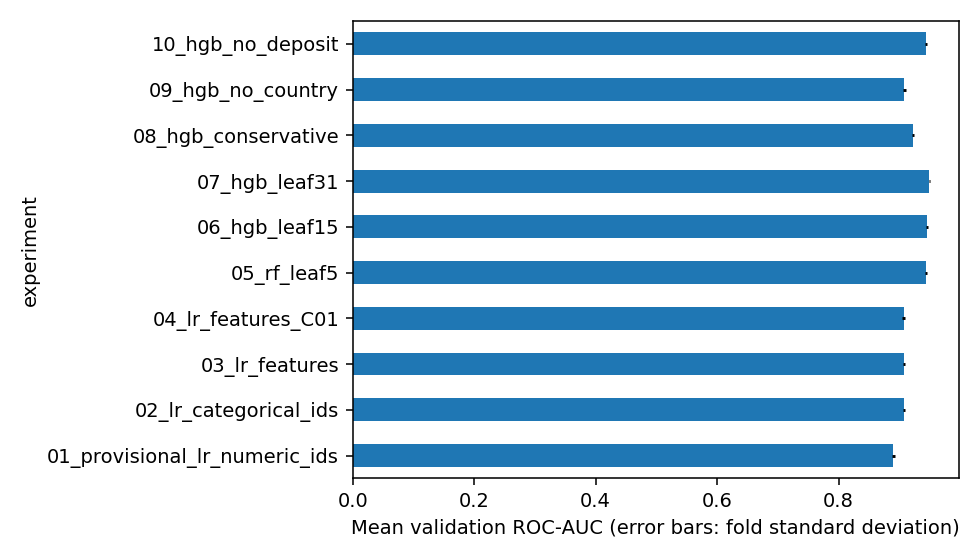

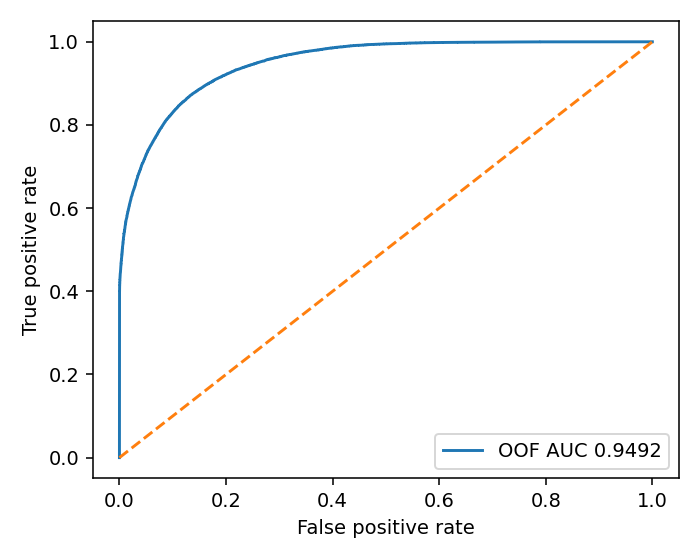

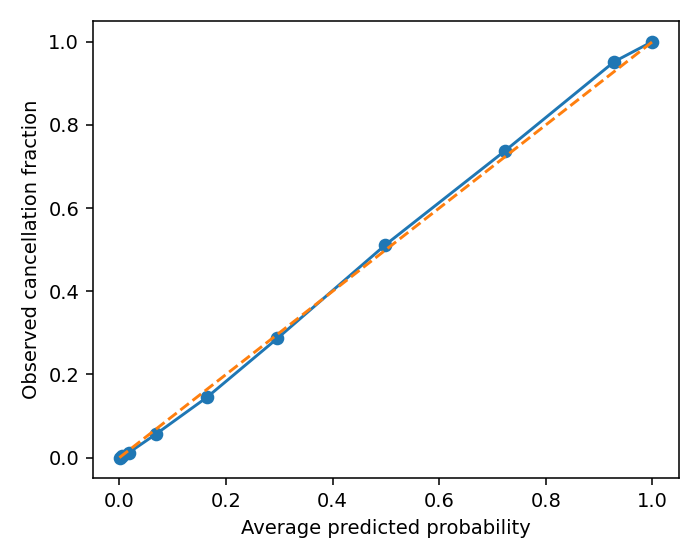

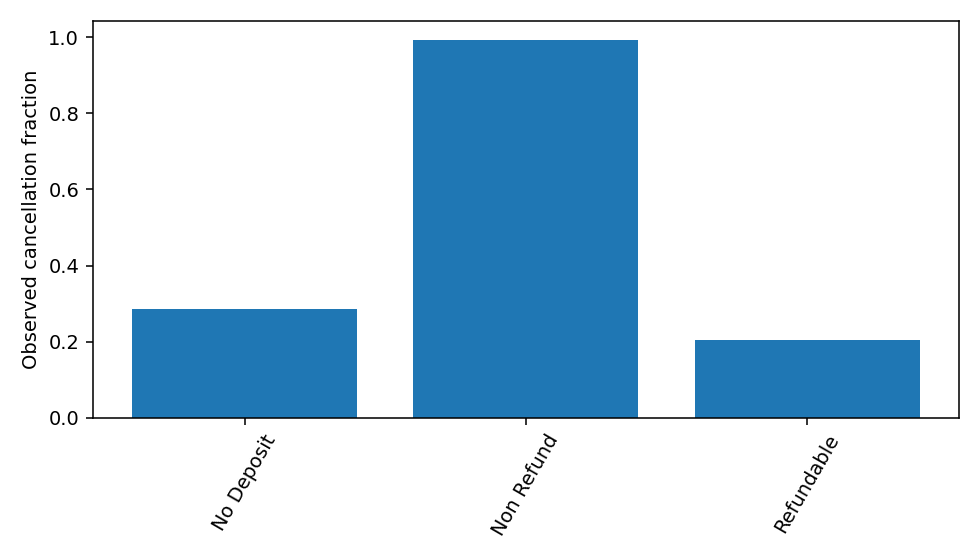

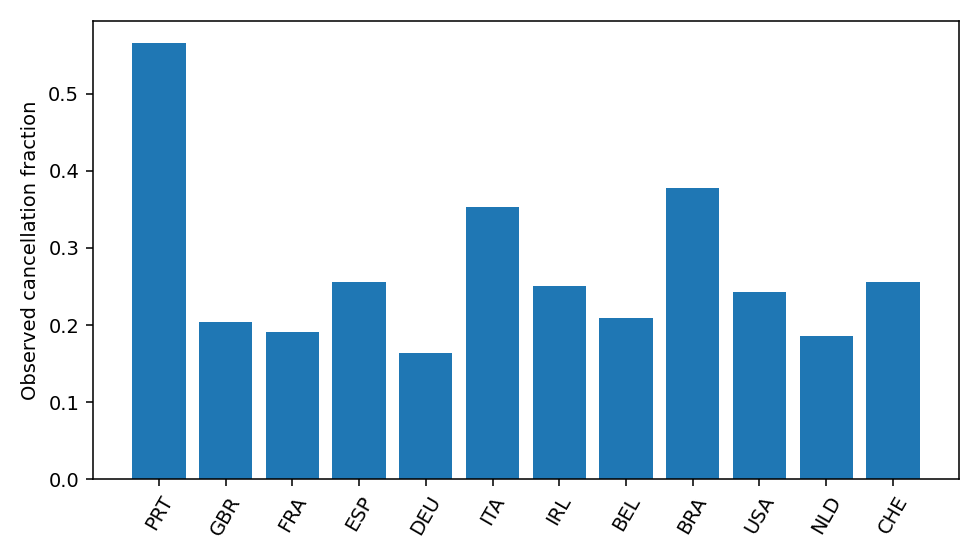

Brier score (smaller is better): 0.08716955688990977


In [11]:
for name in ["deposit_type", "country"]:
    display(pd.read_csv(ROOT / f"reports/{name}_association.csv").head(15))
for name in [
    "model_comparison",
    "validation_roc",
    "validation_calibration",
    "deposit_type_association",
    "country_association",
]:
    display(Image(filename=str(ROOT / f"reports/{name}.png")))
print("Brier score (smaller is better):", results["brier_score"])


### Code cell 12: Verify and optionally download the submission

The SHA256 identifies the exact file. Keep the same bytes for the last Kaggle upload and Canvas. sample_submission.csv has not been verified unless the check below says true.

In [12]:
validation = json.loads((ROOT / "private/submission_validation.json").read_text())
print(json.dumps(validation, indent=2))
assert validation["all_checks_passed"]
assert validation["rows"] == 35817
assert validation["columns"] == ["id", "is_canceled"]
DOWNLOAD_SUBMISSION = False  # Change to True in Colab when ready to download.
if DOWNLOAD_SUBMISSION and "google.colab" in sys.modules:
    files.download(str(ROOT / "private" / validation["file"]))


{
  "file": "TeamHH_submission.csv",
  "rows": 35817,
  "columns": [
    "id",
    "is_canceled"
  ],
  "id_order_matches_test": true,
  "all_checks_passed": true,
  "sample_submission_verified": false,
  "sha256": "3c7524abe8dfcf61029791ddad2110ff5e24ba4a5d42187f437fef44e05b2f37"
}


## Submission and presentation checklist

- Obtain the missing official starter, course notebooks, professor instructions, guide, sample template and memo rubric. Confirm course methods and prediction timing before finalizing.
- First Kaggle submission: **November 2, 2026**. Final predictions: **November 9, 2026, 4:30 PM**. Confirm the professor's timezone; planning uses America/New_York.
- Maximum **five Kaggle submissions per day**. Choose by local validation, not repeated public leaderboard tuning.
- The final Canvas CSV must be the exact file submitted last on Kaggle; compare SHA256 hashes.
- Local CV, public Kaggle and private Kaggle scores are different. No Kaggle scores are recorded here.
- Review `docs/learning_notes.md`, memo draft and presentation outline. Disclose AI assistance. Add accurate teammate names and contributions.
- Do not upload data, per-booking outputs or credentials to GitHub. Review any notebook outputs before sharing. No deployment, business savings, guaranteed score or full-mark claims are supported.